# Dataset Inspection

In this section, we explore the dataset's features, size, and missing values to form our initial assumptions. This overview helps us identify potential correlations and plan how to handle missing data and outliers.

to do that we first import what we need pandas, sqlite3

In [ ]:
import sqlite3
import pandas as pd

Now let's see how the data in data/data.sqlite is made

In [ ]:
db = sqlite3.connect("../data/data.sqlite")

# Sample 5 rows from the Fires table
df_sample = pd.read_sql_query("SELECT * FROM Fires LIMIT 5;", db)

# List all features
print(df_sample.columns.tolist())
display(df_sample)

db.close()

We can start the preprocessing by dropping useless administrative features. We will keep only the following 13 relevant features:

- **Possible Targets**: `STAT_CAUSE_DESCR` (cause), `FIRE_SIZE`, `FIRE_SIZE_CLASS` (size)
- **Time**: `FIRE_YEAR`, `DISCOVERY_DATE`, `DISCOVERY_DOY`, `CONT_DATE`, `CONT_DOY`
- **Space**: `LATITUDE`, `LONGITUDE`, `STATE`, `COUNTY`, `OWNER_DESCR`

In [8]:
db = sqlite3.connect("../data/data.sqlite")

# query to get the good features

cols = "FIRE_YEAR, DISCOVERY_DATE, DISCOVERY_DOY, STAT_CAUSE_DESCR, CONT_DATE, CONT_DOY, FIRE_SIZE, FIRE_SIZE_CLASS, LATITUDE, LONGITUDE, STATE, COUNTY, OWNER_DESCR"
df_sample = pd.read_sql_query(f"SELECT {cols} FROM Fires LIMIT 5;", db)

print(df_sample.columns.tolist())
display(df_sample)


['FIRE_YEAR', 'DISCOVERY_DATE', 'DISCOVERY_DOY', 'STAT_CAUSE_DESCR', 'CONT_DATE', 'CONT_DOY', 'FIRE_SIZE', 'FIRE_SIZE_CLASS', 'LATITUDE', 'LONGITUDE', 'STATE', 'COUNTY', 'OWNER_DESCR']


,FIRE_YEAR,DISCOVERY_DATE,DISCOVERY_DOY,STAT_CAUSE_DESCR,CONT_DATE,CONT_DOY,FIRE_SIZE,FIRE_SIZE_CLASS,LATITUDE,LONGITUDE,STATE,COUNTY,OWNER_DESCR
0,2005,2453403.5,33,Miscellaneous,2453403.5,33,0.10,A,40.036944,-121.005833,CA,63,USFS
1,2004,2453137.5,133,Lightning,2453137.5,133,0.25,A,38.933056,-120.404444,CA,61,USFS
2,2004,2453156.5,152,Debris Burning,2453156.5,152,0.10,A,38.984167,-120.735556,CA,17,STATE OR PRIVATE
3,2004,2453184.5,180,Lightning,2453189.5,185,0.10,A,38.559167,-119.913333,CA,3,USFS
4,2004,2453184.5,180,Lightning,2453189.5,185,0.10,A,38.559167,-119.933056,CA,3,USFS


## Data Explanation

First, we can emphasize that `DISCOVERY_DATE` and `CONT_DATE` are encoded as Julian numbers that we have to decode. Secondly, `FIRE_SIZE_CLASS` is derived from `FIRE_SIZE`. We shouldn't use `FIRE_SIZE_CLASS` since it's less specific than `FIRE_SIZE`.

We can create new features or simplify existing ones. For instance, `DISCOVERY_DOY` can be useful if we treat it as a seasonal value. Assuming there are fewer fires in December than in summer, we can group the [1, 365] range into [1, 4] to represent seasons.

`STAT_CAUSE_DESCR` and `OWNER_DESCR` are text strings, but since they only have a small quantity of possible values, we can convert them using one-hot encoding.

We can also predict links between some features. For instance, it's clear that the duration of the fire ($\Delta = CONT\_DATE - DISCOVERY\_DATE$) is strongly linked to the size of the fire.

Now let's see what values are missing to see if we can use every features and every examples

In [10]:
query = """
SELECT 
    FIRE_YEAR, DISCOVERY_DATE, DISCOVERY_DOY, STAT_CAUSE_DESCR, 
    CONT_DATE, CONT_DOY, FIRE_SIZE, FIRE_SIZE_CLASS, 
    LATITUDE, LONGITUDE, STATE, COUNTY, OWNER_DESCR
FROM Fires;
"""

df = pd.read_sql_query(query, db)
print(df.isnull().sum())

FIRE_YEAR                0
DISCOVERY_DATE           0
DISCOVERY_DOY            0
STAT_CAUSE_DESCR         0
CONT_DATE           891531
CONT_DOY            891531
FIRE_SIZE                0
FIRE_SIZE_CLASS          0
LATITUDE                 0
LONGITUDE                0
STATE                    0
COUNTY              678148
OWNER_DESCR              0
dtype: int64


As we can see, `CONT_DATE` and `CONT_DOY` have 891,531 missing values. That's nearly 40% of the dataset, so replacing them with the mean isn't a viable option. We have to either drop the features entirely or drop the incomplete rows. 

If we drop the rows missing these dates and `COUNTY`, we will still have around 1 million examples left. That is more than enough data to train a solid model.

In [ ]:
df_clean = df.dropna()

print(f"Lignes restantes : {len(df_clean)}")
print(f"Pourcentage conservé : {round(len(df_clean) / len(df) * 100, 2)}%")

Finally, we still have around 670k examples, which is more than enough to train our models.

## Feature Correlations

Next, we will use a correlation matrix to identify potential relationships between our features.

To do that we want to have numerical value to find the correlation then moreover the numerical value we turn our text values in one hot encoding value.

We also talked about a new feature named ($\Delta = CONT\_DATE - DISCOVERY\_DATE$)  we add it.

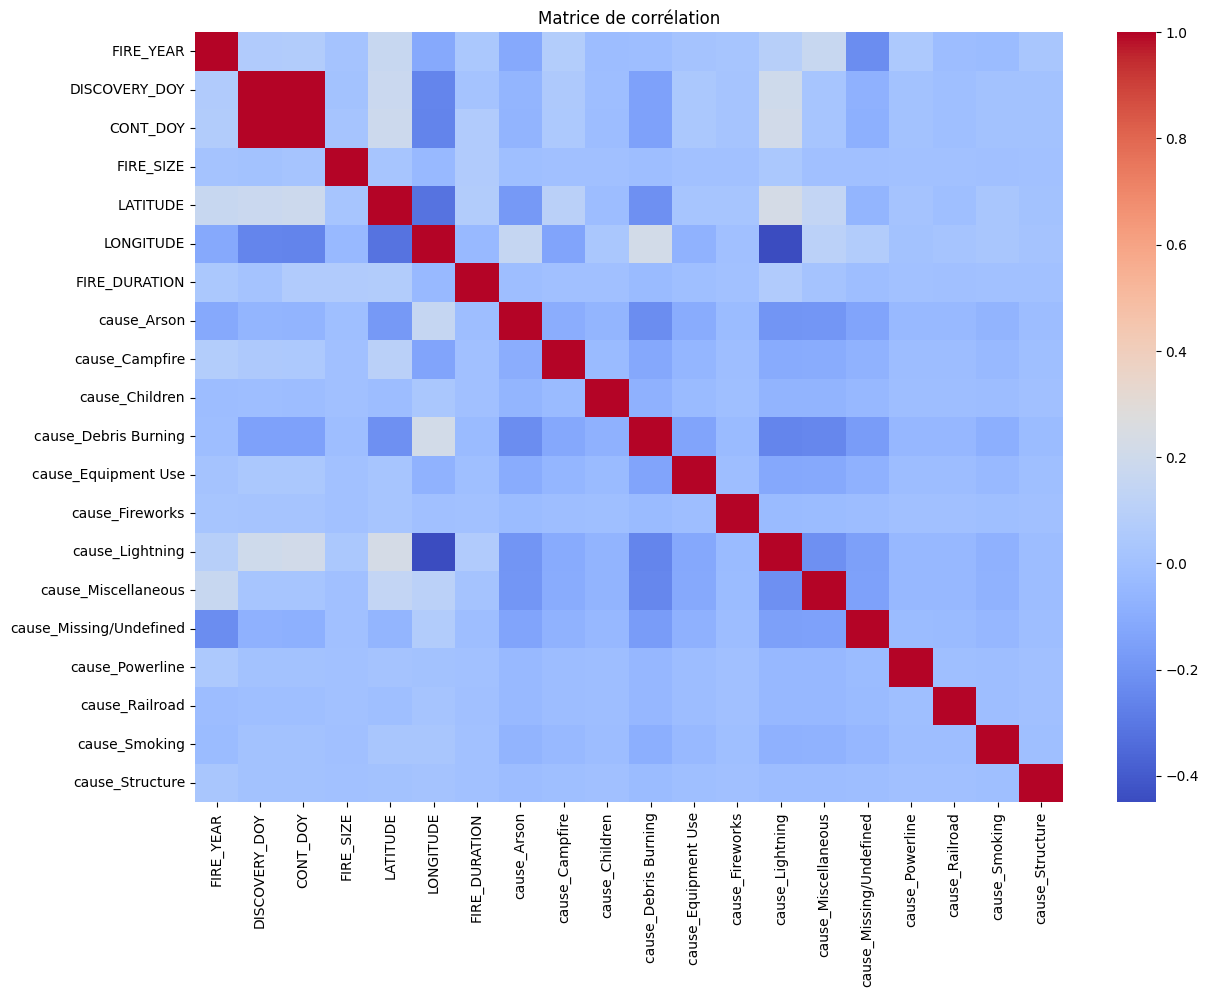

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = ['FIRE_YEAR', 'DISCOVERY_DOY', 'CONT_DOY', 'FIRE_SIZE', 'LATITUDE', 'LONGITUDE']
df_numeric = df_clean[numeric_cols].copy()

# One-hot encoding 
causes_ohe = pd.get_dummies(df_clean['STAT_CAUSE_DESCR'], prefix='cause')

# new feature
df_numeric['FIRE_DURATION'] = df_clean['CONT_DATE'] - df_clean['DISCOVERY_DATE']

df_final = pd.concat([df_numeric, causes_ohe], axis=1)
corr_matrix = df_final.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap='coolwarm')
plt.title("Matrice de corrélation")
plt.show()

These results are interesting: as expected, `DISCOVERY_DATE` and `CONT_DATE` are highly correlated, but the new `FIRE_DURATION` feature appears mostly independent. We also notice an unexpected link between `cause_Lightning` and `LONGITUDE`.

To uncover more complex patterns, we can discretize `DISCOVERY_DOY` into four seasons. This should reveal seasonal dependencies for specific fire causes.

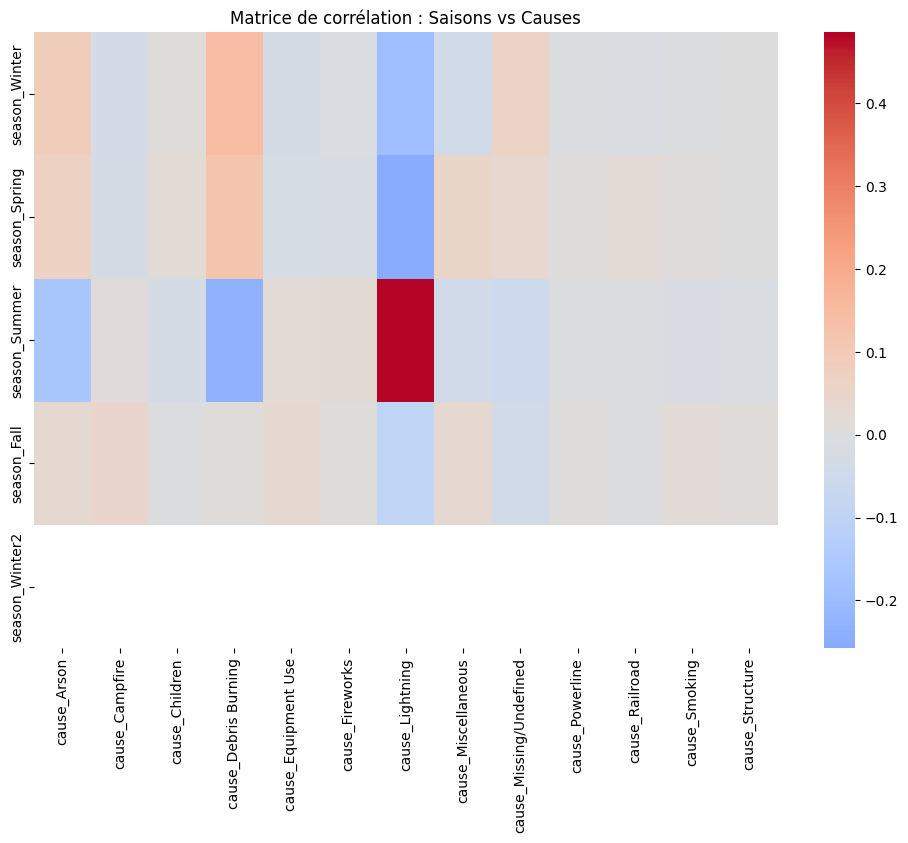

In [ ]:
bins = [0, 60, 152, 244, 335, 366]
labels = ['Winter', 'Spring', 'Summer', 'Fall', 'Winter2']

df_clean['SEASON'] = pd.cut(df_clean['DISCOVERY_DOY'], bins=bins, labels=labels, ordered=False)
df_clean['SEASON'] = df_clean['SEASON'].replace('Winter2', 'Winter') # Fusionner la fin et le début d'année

seasons_ohe = pd.get_dummies(df_clean['SEASON'], prefix='season')

df_seasons_causes = pd.concat([seasons_ohe, causes_ohe], axis=1)
corr_seasons = df_seasons_causes.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_seasons.loc[seasons_ohe.columns, causes_ohe.columns], cmap='coolwarm', center=0, annot=False)
plt.title("Matrice de corrélation : Saisons vs Causes")
plt.show()

The heatmap clearly shows how seasons impact fire causes

* **Summer**: Strongly correlated with lightning (the dark red square). On the flip side, human-driven causes like arson or debris burning are at their lowest[cite: 1].
* **Spring and Winter**: The trend reverses. Lightning is rare, but arson and debris fires are much more frequent.



We will now visualize the strongest relationships identified in the correlation matrix. The highest correlation is naturally between `DISCOVERY_DOY` and `CONT_DOY`. Plotting this relationship helps confirm the linear trend and easily exposes anomalies, such as fires discovered late in the year but contained early the following year. It will help to do Feature Engineering. 

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean, 
    x='DISCOVERY_DOY', 
    y='CONT_DOY', 
    alpha=0.1, 
    edgecolor=None,
    s=15
)

plt.plot([0, 365], [0, 365], color='red', linestyle='--', linewidth=2, label='Same Day Containment')

plt.title("Relationship between Discovery DOY and Containment DOY")
plt.xlabel("Discovery Day of Year")
plt.ylabel("Containment Day of Year")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

It's actually more interesting than it seems at first glance. Even though most fires are small and contained on the same day (clustered right on the red line), a significant portion takes much longer to extinguish, scattering far above the line. Finally, the points in the bottom right corner represent cross-year fires that started late in the year and were contained early the next year. This visually proves why using raw `CONT_DOY` is a trap and justifies our custom `FIRE_DURATION` feature. However we can try to use these features at the end to see if our models generalize better.

#Preprocessing

Since our target is the size of the fire we have two things to check, the distribution of the size of the fire if 99% of fire are small and 1% big our generalization can be bad and we have to take into account that. And we need to see the outliers.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_clean['FIRE_SIZE'].hist(bins=50, ax=axes[0])
axes[0].set_title('FIRE_SIZE (Brut)')

np.log1p(df_clean['FIRE_SIZE']).hist(bins=50, ax=axes[1])
axes[1].set_title('Log(FIRE_SIZE)')

plt.show()

As we can think most of the fires are very small it explains the link between the day of apparaition and the day of controll but it's going to be an issue to have a good generalization.

FIRE_DURATION
0      564339
1       58242
2       14205
3        7160
4        4201
        ...  
235         1
231         1
265         1
298         1
397         1
Name: count, Length: 304, dtype: int64


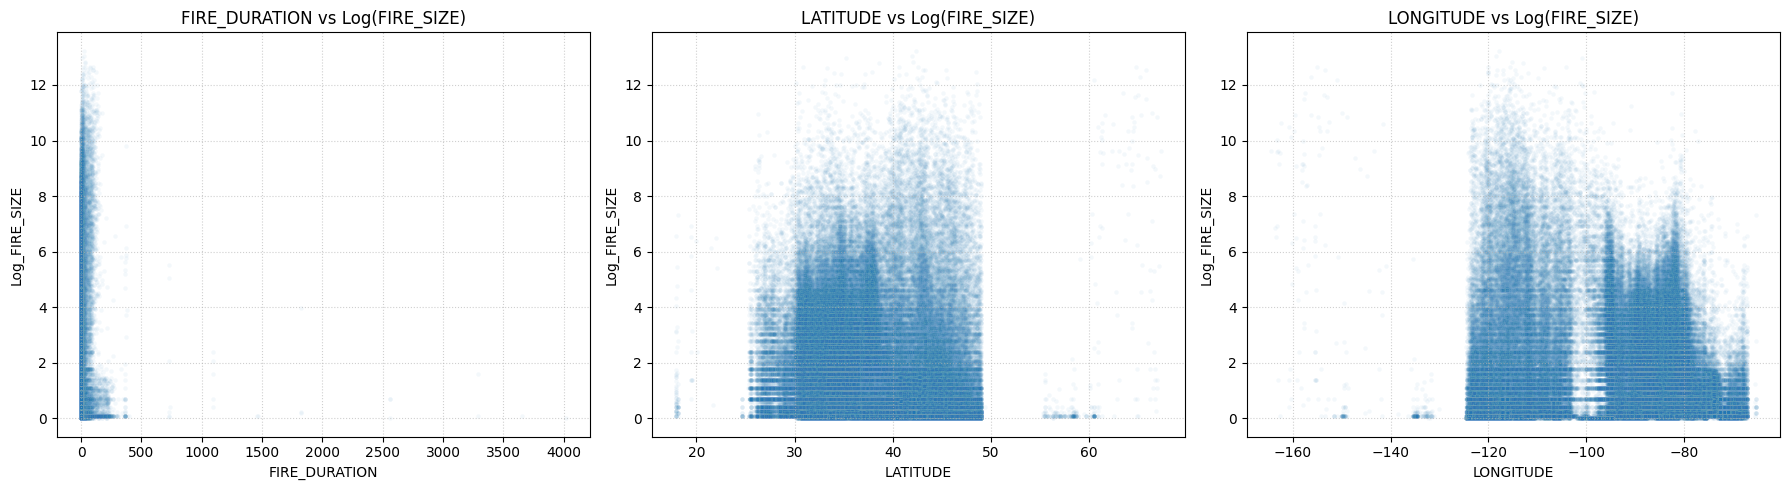

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_clean['CONT_DATE'] = pd.to_datetime(df_clean['CONT_DATE'])
df_clean['DISCOVERY_DATE'] = pd.to_datetime(df_clean['DISCOVERY_DATE'])

df_clean['FIRE_DURATION'] = df_clean['CONT_DATE'].astype('int64') - df_clean['DISCOVERY_DATE'].astype('int64')

# Target
df_clean['Log_FIRE_SIZE'] = np.log1p(df_clean['FIRE_SIZE'])

# plot
features = ['FIRE_DURATION', 'LATITUDE', 'LONGITUDE']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(features):
    sns.scatterplot(data=df_clean, x=feature, y='Log_FIRE_SIZE', alpha=0.05, s=10, ax=axes[i])
    axes[i].set_title(f'{feature} vs Log(FIRE_SIZE)')
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

We see there is outliers in fire duration with some of them with 3000 more days. For latitude and longitude there is ouliers but its  the representation of states like Hawaï or Alaska. We can keep them they have precious information. In Alaska it's more cold and hawaï we are in the middle of Ocean

In [ ]:
df_clean = df_clean[df_clean['FIRE_DURATION'] <= 365]

In [40]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd


features = [
    'FIRE_YEAR', 'DISCOVERY_DOY', 'FIRE_DURATION', 
    'LATITUDE', 'LONGITUDE', 'STATE', 
    'STAT_CAUSE_DESCR', 'OWNER_DESCR'
]

X = df_clean[features]
y = df_clean['Log_FIRE_SIZE']

X_encoded = pd.get_dummies(X, columns=['STATE', 'STAT_CAUSE_DESCR', 'OWNER_DESCR'], drop_first=True)

# 1. Split off 30% for validation + test
X_train, X_temp, y_train, y_temp = train_test_split(X_encoded, y, test_size=0.3, random_state=42)

# 2. Split the 30% in half to get 15% Validation and 15% Test
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)


scaler = StandardScaler()
num_cols = ['FIRE_YEAR', 'DISCOVERY_DOY', 'FIRE_DURATION', 'LATITUDE', 'LONGITUDE']

# 3. Standardize based ONLY on the training set
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols] = scaler.transform(X_val[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])


print(f"Training set: {X_train.shape[0]} rows, {X_train.shape[1]} features")
print(f"Test set: {X_test.shape[0]} rows, {X_test.shape[1]} features")

Training set: 468757 rows, 81 features
Test set: 100449 rows, 81 features


Now we have our dataset and now we have done our preprocessing we are going to propose some models to see if they work.
let's try simple models like linear regression and linear SVM

In [41]:
import numpy as np
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

lr = LinearRegression()
svm_lin = SGDRegressor(epsilon=0, max_iter=1000, random_state=42)

lr.fit(X_train, y_train)
svm_lin.fit(X_train, y_train)

models = {'Linear Regression': lr, 'Linear SVM (SGD)': svm_lin}

for name, model in models.items():
    y_pred = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    mae = mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    
    print(f"--- {name} ---")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE : {mae:.4f}")
    print(f"R²  : {r2:.4f}\n")

--- Linear Regression ---
RMSE: 1.2508
MAE : 0.8407
R²  : 0.1705

--- Linear SVM (SGD) ---
RMSE: 1.2630
MAE : 0.8373
R²  : 0.1543



scores are weak, the R² score show that the model is just slightly better than a model who take the mean. Let's try more complex model to understand better.

In [42]:
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Grille d'hyperparamètres
param_grid = [
    {
        'kernel': ['poly'],
        'degree': [2, 3],
        'C': [0.1, 1, 10],
        'epsilon': [0.01, 0.1],
        'gamma': ['scale', 'auto']
    },
    {
        'kernel': ['rbf'],
        'C': [0.1, 1, 10],
        'epsilon': [0.01, 0.1],
        'gamma': ['scale', 'auto']
    }
]

grid = GridSearchCV(
    estimator=SVR(),
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print(f"Meilleurs paramètres : {grid.best_params_}")
print(f"Meilleur R² en CV : {grid.best_score_:.4f}\n")

# Évaluation sur la validation
best_svr = grid.best_estimator_
y_pred = best_svr.predict(X_val)

print("--- Meilleur SVR (Validation) ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, y_pred)):.4f}")
print(f"MAE : {mean_absolute_error(y_val, y_pred):.4f}")
print(f"R²  : {r2_score(y_val, y_pred):.4f}")

Fitting 3 folds for each of 36 candidates, totalling 108 fits


: 

: 

: 